<a href="https://colab.research.google.com/github/revak18/nicotine_use_mathmodel/blob/main/NicotineUse_SIR_DDE_Model_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Initial setup

In [1]:
!pip install ddeint

#E-Cigarette Simulation

In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
from ddeint import ddeint

# Product type for simulation
product_type = 'EC'  # Change to 'C' for cigarettes

# Constants
B = 0.00103  # Birth rate per month
mu = 0.0006657  # Death rate per month
aging_rate_y_to_ya = 1 / (7 * 12)  # Years to transition from youth to young adult
aging_rate_ya_to_a = 1 / (5 * 12)  # Years to transition from young adult to adult
tau_1, tau_2, tau_3 = 12, 6, 12  # Delays for infection, recovery, and relapse

# Seed for reproducibility
random.seed(42)
np.random.seed(42)

# Function to generate linearly spaced integers
def linspace_integers(start, stop, num):
    """Generate a linearly spaced array of integers."""
    step = (stop - start) // (num - 1)  # Calculate step using integer division
    return np.arange(start, stop + step, step, dtype=int)

# Generate time points
t = linspace_integers(0, 419, 420)

# Function to calculate beta values - Infection
def beta_values(t):
    if product_type == 'EC':
        return 0.18 + (random.random() / 100) * np.cos(t / 12 * np.pi)
    else:
        return 0.003 + (random.random() / 1000) * np.cos(t / 12 * np.pi)

# Function to calculate gamma values - Recovery
def gamma_values(t):
    if product_type == 'EC':
        return (1.333 ** (1 / 12) - 1) + (random.random() / 100) * np.cos(t / 12 * np.pi)
    else:
        return (1.677 ** (1 / 12) - 1) + (random.random() / 100) * np.cos(t / 12 * np.pi)

# Function to calculate rho values - Relapse
def rho_values(t):
    if product_type == 'EC':
        return (1.600 ** (1 / 12) - 1) + (random.random() / 100) * np.cos(t / 12 * np.pi)
    else:
        return (1.912 ** (1 / 12) - 1) + (random.random() / 100) * np.cos(t / 12 * np.pi)

# Calculate parameter arrays
beta = np.array([beta_values(t_i) for t_i in t])
gamma = np.array([gamma_values(t_i) for t_i in t])
rho = np.array([rho_values(t_i) for t_i in t])

if product_type == 'EC':
   print('E-Cigarettes')
else:
   print('Cigarettes')
# Output the first calculated value for beta, gamma, and rho for verification
print("First beta value:", beta[0])
print("First gamma value:", gamma[0])
print("First rho value:", rho[0])

E-Cigarettes
First beta value: 0.18639426798457884
First gamma value: 0.028386249589237703
First rho value: 0.043329720031018586


In [3]:
def model(Y, t):
    S_y, I_y, R_y, S_ya, I_ya, R_ya, S_a, I_a, R_a = Y(t)

    # Accessing delayed values using indexing
    if t >= tau_1:
        S_y_delay = Y(t - tau_1)[0]
        I_y_delay = Y(t - tau_1)[1]
    else:
        S_y_delay = S_y
        I_y_delay = I_y

    if t >= tau_2:
        I_y_delay2 = Y(t - tau_2)[1]
        I_ya_delay2 = Y(t - tau_2)[4]
        I_a_delay2 = Y(t - tau_2)[7]
    else:
        I_y_delay2 = I_y
        I_ya_delay2 = I_ya
        I_a_delay2 = I_a

    if t >= tau_3:
        R_y_delay3 = Y(t - tau_3)[2]
        R_ya_delay3 = Y(t - tau_3)[5]
        R_a_delay3 = Y(t - tau_3)[8]
    else:
        R_y_delay3 = R_y
        R_ya_delay3 = R_ya
        R_a_delay3 = R_a

    t = int(t)

    # Population dynamics
    dS_y_dt = B - beta[t] * S_y * I_y_delay - mu * S_y - aging_rate_y_to_ya * S_y
    dI_y_dt = beta[t] * S_y * I_y_delay - (mu + gamma[t]) * I_y + rho[t] * R_y_delay3 - aging_rate_y_to_ya * I_y
    dR_y_dt = gamma[t] * I_y_delay2 - (mu + rho[t]) * R_y - aging_rate_y_to_ya * R_y

    dS_ya_dt = S_y * aging_rate_y_to_ya - beta[t] * S_ya * I_y_delay - mu * S_ya - aging_rate_ya_to_a * S_ya
    dI_ya_dt = I_y * aging_rate_y_to_ya + beta[t] * S_ya * I_y_delay - (mu + gamma[t]) * I_ya - aging_rate_ya_to_a * I_ya
    dR_ya_dt = R_y * aging_rate_y_to_ya + gamma[t] * I_ya_delay2 - (mu + rho[t]) * R_ya_delay3 - aging_rate_ya_to_a * R_ya

    dS_a_dt = S_ya * aging_rate_ya_to_a - beta[t] * S_a * I_a - mu * S_a
    dI_a_dt = I_ya * aging_rate_ya_to_a + beta[t] * S_a * I_a - (mu + gamma[t]) * I_a_delay2
    dR_a_dt = R_ya * aging_rate_ya_to_a + gamma[t] * I_a_delay2 - (mu + rho[t]) * R_a_delay3

    return [dS_y_dt, dI_y_dt, dR_y_dt, dS_ya_dt, dI_ya_dt, dR_ya_dt, dS_a_dt, dI_a_dt, dR_a_dt]

def history(t):
    if product_type == 'EC':    # E-Cigarettes
       return [0.8000, 0.2000, 0.0000, 0.9400, 0.0600, 0.0000, 0.9400, 0.0600, 0.0000]  # Initial values for E-cigarettes all states of Youth, Young Adults and Adults as of 2022
    else:    # Cigarettes
       return [0.9170, 0.0830, 0.0000, 0.8840, 0.1160, 0.0000, 0.8840, 0.1160, 0.0000]  # Initial values for Cigarettes all states of Youth, Young Adults and Adults as of 2022

# Solve DDE
t = np.linspace(0, 120, 120)  # Simulate for 10 years
t = t.astype('int32')
sol = ddeint(model, history, t)

totals = sol.sum(axis=1)
sol /= totals[:, None]

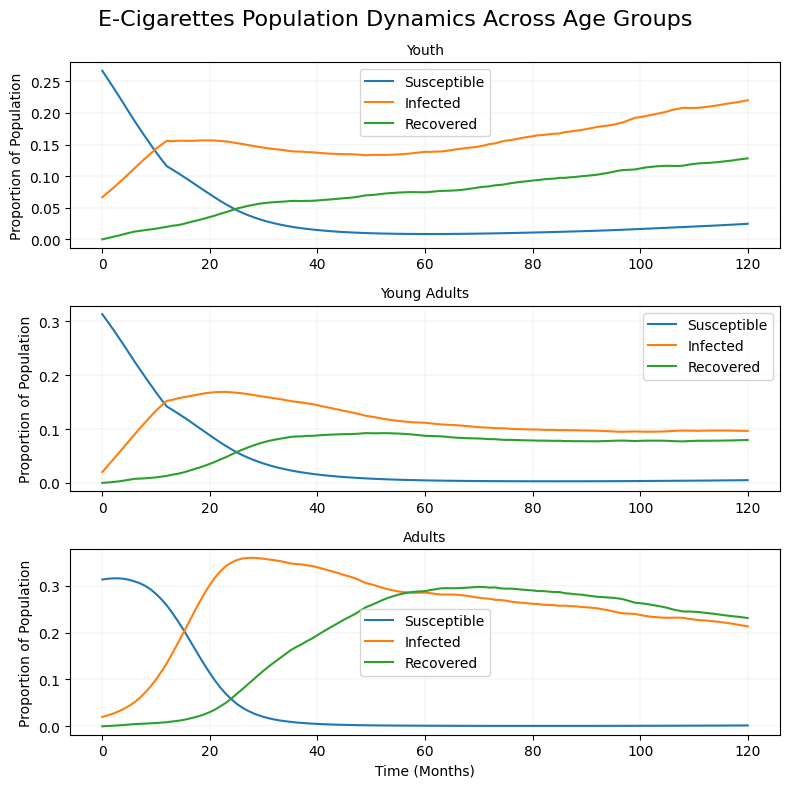

In [4]:
# Plotting results
plt.figure(figsize=(8, 8))
# Subplot for Youth
plt.subplot(3, 1, 1)
plt.plot(t, sol[:, 0], label='Susceptible')
plt.plot(t, sol[:, 1], label='Infected')
plt.plot(t, sol[:, 2], label='Recovered')
plt.title('Youth', fontsize=10)
plt.ylabel('Proportion of Population')
plt.legend()
plt.grid(True)
plt.grid(color='gray', linestyle='dashed', linewidth=0.1)

# Subplot for Young Adults
plt.subplot(3, 1, 2)
plt.plot(t, sol[:, 3], label='Susceptible')
plt.plot(t, sol[:, 4], label='Infected')
plt.plot(t, sol[:, 5], label='Recovered')
plt.title('Young Adults', fontsize=10)
plt.ylabel('Proportion of Population')
plt.legend()
plt.grid(True)
plt.grid(color='gray', linestyle='dashed', linewidth=0.1)

# Subplot for Adults
plt.subplot(3, 1, 3)
plt.plot(t, sol[:, 6], label='Susceptible')
plt.plot(t, sol[:, 7], label='Infected')
plt.plot(t, sol[:, 8], label='Recovered')
plt.title('Adults', fontsize=10)
plt.xlabel('Time (Months)')
plt.ylabel('Proportion of Population')
plt.legend()
plt.grid(True)
plt.grid(color='gray', linestyle='dashed', linewidth=0.1)

if product_type == 'EC':    # E-Cigarettes
   stitle = 'E-Cigarettes Population Dynamics Across Age Groups'
else:                       # Cigarettes
   stitle = 'Cigarettes Population Dynamics Across Age Groups'
plt.suptitle(stitle, fontsize=16)
plt.tight_layout()
plt.show()

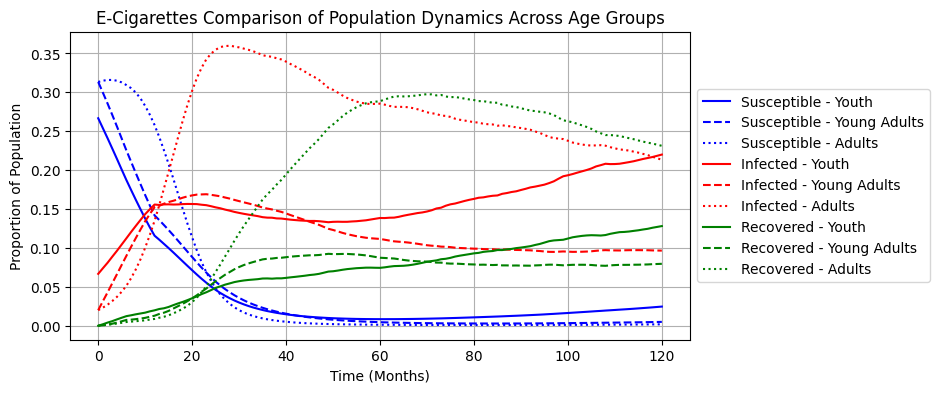

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming 't' and 'sol' are defined as per your model output
# t = np.linspace(0, 120, 120)  # Time array
# sol = np.random.rand(120, 9)  # Solution array with different compartments

plt.figure(figsize=(8, 4))
states = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']

# Plotting each state for all age groups
for i, state in enumerate(states):
    plt.plot(t, sol[:, i], label=f'{state} - Youth', color=colors[i], linestyle='-')
    plt.plot(t, sol[:, i + 3], label=f'{state} - Young Adults', color=colors[i], linestyle='--')
    plt.plot(t, sol[:, i + 6], label=f'{state} - Adults', color=colors[i], linestyle=':')

if product_type == 'EC':    # E-Cigarettes
   stitle = 'E-Cigarettes Comparison of Population Dynamics Across Age Groups'
else:                       # Cigarettes
   stitle = 'Cigarettes Comparison of Population Dynamics Across Age Groups'

plt.title(stitle)
plt.xlabel('Time (Months)')
plt.ylabel('Proportion of Population')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True)
plt.show()

In [9]:
# Define the start year
start_year = 2023

# Extract years of interest
years_of_interest = [2023]

# Calculate corresponding indices for 2023 and 2024 in the time array (t is in months)
indices_of_interest = [(year - start_year) * 12 for year in years_of_interest]

# Extract the model's predictions for the "Infected" category for Youth
predicted_infected_youth = [sol[idx, 1] * 100 for idx in indices_of_interest]

# CDC reported values for comparison
cdc_reported_values = {
    2023: 7.7,
    2024: 5.9
}

# Print model predictions and CDC reported values
print(f"Model Predictions vs CDC Reported Values (Infected Youth - E-Cigarettes):")
for year, idx, predicted in zip(years_of_interest, indices_of_interest, predicted_infected_youth):
    print(f"Year: {year}")
    print(f"  - Model Predicted (Youth Infected): {predicted:.2f}%")
    print(f"  - CDC Reported: {cdc_reported_values[year]}%\n")

Model Predictions vs CDC Reported Values (Infected Youth - E-Cigarettes):
Year: 2023
  - Model Predicted (Youth Infected): 6.67%
  - CDC Reported: 7.7%



#Cigarette Simulation

In [10]:
import numpy as np
import random
import matplotlib.pyplot as plt
from ddeint import ddeint

# Product type for simulation
product_type = 'C'  # Change to 'C' for cigarettes

# Constants
B = 0.00103  # Birth rate per month
mu = 0.0006657  # Death rate per month
aging_rate_y_to_ya = 1 / (7 * 12)  # Years to transition from youth to young adult
aging_rate_ya_to_a = 1 / (5 * 12)  # Years to transition from young adult to adult
tau_1, tau_2, tau_3 = 12, 6, 12  # Delays for infection, recovery, and relapse

# Seed for reproducibility
random.seed(42)
np.random.seed(42)

# Function to generate linearly spaced integers
def linspace_integers(start, stop, num):
    """Generate a linearly spaced array of integers."""
    step = (stop - start) // (num - 1)  # Calculate step using integer division
    return np.arange(start, stop + step, step, dtype=int)

# Generate time points
t = linspace_integers(0, 419, 420)

# Function to calculate beta values - Infection
def beta_values(t):
    if product_type == 'EC':
        return 0.18 + (random.random() / 100) * np.cos(t / 12 * np.pi)
    else:
        return 0.003 + (random.random() / 1000) * np.cos(t / 12 * np.pi)

# Function to calculate gamma values - Recovery
def gamma_values(t):
    if product_type == 'EC':
        return (1.333 ** (1 / 12) - 1) + (random.random() / 100) * np.cos(t / 12 * np.pi)
    else:
        return (1.677 ** (1 / 12) - 1) + (random.random() / 100) * np.cos(t / 12 * np.pi)

# Function to calculate rho values - Relapse
def rho_values(t):
    if product_type == 'EC':
        return (1.600 ** (1 / 12) - 1) + (random.random() / 100) * np.cos(t / 12 * np.pi)
    else:
        return (1.912 ** (1 / 12) - 1) + (random.random() / 100) * np.cos(t / 12 * np.pi)

# Calculate parameter arrays
beta = np.array([beta_values(t_i) for t_i in t])
gamma = np.array([gamma_values(t_i) for t_i in t])
rho = np.array([rho_values(t_i) for t_i in t])

if product_type == 'EC':
   print('E-Cigarettes')
else:
   print('Cigarettes')
# Output the first calculated value for beta, gamma, and rho for verification
print("First beta value:", beta[0])
print("First gamma value:", gamma[0])
print("First rho value:", rho[0])

Cigarettes
First beta value: 0.003639426798457884
First gamma value: 0.04816986743081948
First rho value: 0.05888339183070972


In [11]:
def model(Y, t):
    S_y, I_y, R_y, S_ya, I_ya, R_ya, S_a, I_a, R_a = Y(t)

    # Accessing delayed values using indexing
    if t >= tau_1:
        S_y_delay = Y(t - tau_1)[0]
        I_y_delay = Y(t - tau_1)[1]
    else:
        S_y_delay = S_y
        I_y_delay = I_y

    if t >= tau_2:
        I_y_delay2 = Y(t - tau_2)[1]
        I_ya_delay2 = Y(t - tau_2)[4]
        I_a_delay2 = Y(t - tau_2)[7]
    else:
        I_y_delay2 = I_y
        I_ya_delay2 = I_ya
        I_a_delay2 = I_a

    if t >= tau_3:
        R_y_delay3 = Y(t - tau_3)[2]
        R_ya_delay3 = Y(t - tau_3)[5]
        R_a_delay3 = Y(t - tau_3)[8]
    else:
        R_y_delay3 = R_y
        R_ya_delay3 = R_ya
        R_a_delay3 = R_a

    t = int(t)

    # Population dynamics
    dS_y_dt = B - beta[t] * S_y * I_y_delay - mu * S_y - aging_rate_y_to_ya * S_y
    dI_y_dt = beta[t] * S_y * I_y_delay - (mu + gamma[t]) * I_y + rho[t] * R_y_delay3 - aging_rate_y_to_ya * I_y
    dR_y_dt = gamma[t] * I_y_delay2 - (mu + rho[t]) * R_y - aging_rate_y_to_ya * R_y

    dS_ya_dt = S_y * aging_rate_y_to_ya - beta[t] * S_ya * I_y_delay - mu * S_ya - aging_rate_ya_to_a * S_ya
    dI_ya_dt = I_y * aging_rate_y_to_ya + beta[t] * S_ya * I_y_delay - (mu + gamma[t]) * I_ya - aging_rate_ya_to_a * I_ya
    dR_ya_dt = R_y * aging_rate_y_to_ya + gamma[t] * I_ya_delay2 - (mu + rho[t]) * R_ya_delay3 - aging_rate_ya_to_a * R_ya

    dS_a_dt = S_ya * aging_rate_ya_to_a - beta[t] * S_a * I_a - mu * S_a
    dI_a_dt = I_ya * aging_rate_ya_to_a + beta[t] * S_a * I_a - (mu + gamma[t]) * I_a_delay2
    dR_a_dt = R_ya * aging_rate_ya_to_a + gamma[t] * I_a_delay2 - (mu + rho[t]) * R_a_delay3

    return [dS_y_dt, dI_y_dt, dR_y_dt, dS_ya_dt, dI_ya_dt, dR_ya_dt, dS_a_dt, dI_a_dt, dR_a_dt]

def history(t):
    if product_type == 'EC':    # E-Cigarettes
       return [0.8000, 0.2000, 0.0000, 0.9400, 0.0600, 0.0000, 0.9400, 0.0600, 0.0000]  # Initial values for E-cigarettes all states of Youth, Young Adults and Adults as of 2022
    else:    # Cigarettes
       return [0.9170, 0.0830, 0.0000, 0.8840, 0.1160, 0.0000, 0.8840, 0.1160, 0.0000]  # Initial values for Cigarettes all states of Youth, Young Adults and Adults as of 2022

# Solve DDE
t = np.linspace(0, 120, 120)  # Simulate for 10 years
t = t.astype('int32')
sol = ddeint(model, history, t)

totals = sol.sum(axis=1)
sol /= totals[:, None]

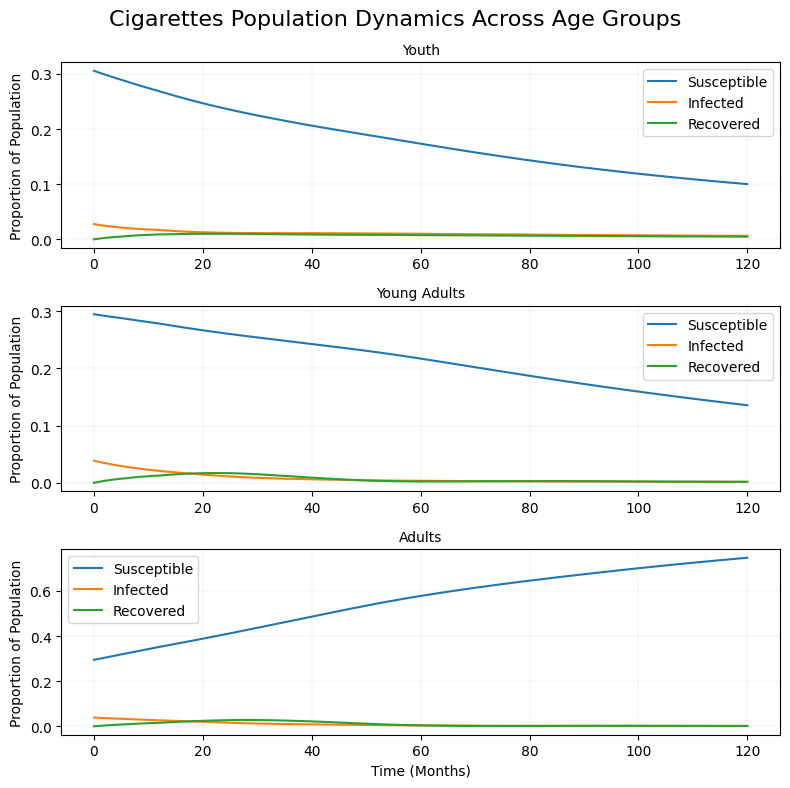

In [12]:
# Plotting results
plt.figure(figsize=(8, 8))
# Subplot for Youth
plt.subplot(3, 1, 1)
plt.plot(t, sol[:, 0], label='Susceptible')
plt.plot(t, sol[:, 1], label='Infected')
plt.plot(t, sol[:, 2], label='Recovered')
plt.title('Youth', fontsize=10)
plt.ylabel('Proportion of Population')
plt.legend()
plt.grid(True)
plt.grid(color='gray', linestyle='dashed', linewidth=0.1)

# Subplot for Young Adults
plt.subplot(3, 1, 2)
plt.plot(t, sol[:, 3], label='Susceptible')
plt.plot(t, sol[:, 4], label='Infected')
plt.plot(t, sol[:, 5], label='Recovered')
plt.title('Young Adults', fontsize=10)
plt.ylabel('Proportion of Population')
plt.legend()
plt.grid(True)
plt.grid(color='gray', linestyle='dashed', linewidth=0.1)

# Subplot for Adults
plt.subplot(3, 1, 3)
plt.plot(t, sol[:, 6], label='Susceptible')
plt.plot(t, sol[:, 7], label='Infected')
plt.plot(t, sol[:, 8], label='Recovered')
plt.title('Adults', fontsize=10)
plt.xlabel('Time (Months)')
plt.ylabel('Proportion of Population')
plt.legend()
plt.grid(True)
plt.grid(color='gray', linestyle='dashed', linewidth=0.1)

if product_type == 'EC':    # E-Cigarettes
   stitle = 'E-Cigarettes Population Dynamics Across Age Groups'
else:                       # Cigarettes
   stitle = 'Cigarettes Population Dynamics Across Age Groups'
plt.suptitle(stitle, fontsize=16)
plt.tight_layout()
plt.show()

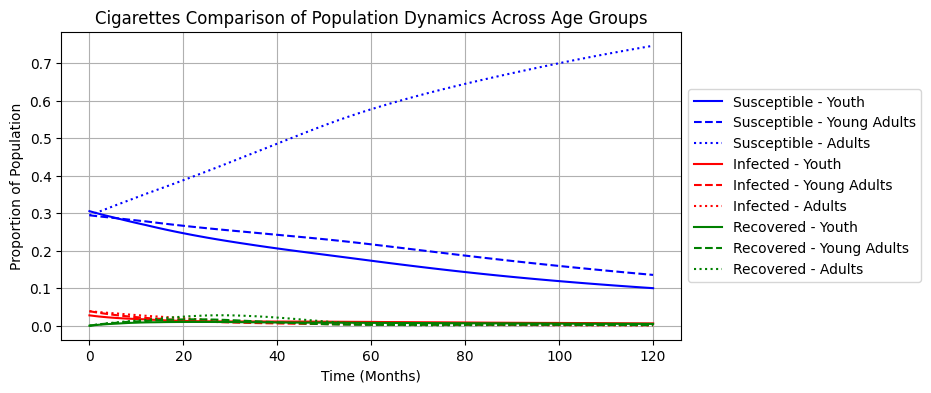

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming 't' and 'sol' are defined as per your model output
# t = np.linspace(0, 120, 120)  # Time array
# sol = np.random.rand(120, 9)  # Solution array with different compartments

plt.figure(figsize=(8, 4))
states = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']

# Plotting each state for all age groups
for i, state in enumerate(states):
    plt.plot(t, sol[:, i], label=f'{state} - Youth', color=colors[i], linestyle='-')
    plt.plot(t, sol[:, i + 3], label=f'{state} - Young Adults', color=colors[i], linestyle='--')
    plt.plot(t, sol[:, i + 6], label=f'{state} - Adults', color=colors[i], linestyle=':')

if product_type == 'EC':    # E-Cigarettes
   stitle = 'E-Cigarettes Comparison of Population Dynamics Across Age Groups'
else:                       # Cigarettes
   stitle = 'Cigarettes Comparison of Population Dynamics Across Age Groups'

plt.title(stitle)
plt.xlabel('Time (Months)')
plt.ylabel('Proportion of Population')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True)
plt.show()

In [16]:
# Define the start year (2022)
start_year = 2023

# Extract years of interest
years_of_interest = [2023]

# Calculate corresponding indices for 2023 and 2024 in the time array (t is in months)
indices_of_interest = [(year - start_year) * 12 for year in years_of_interest]

# Extract the model's predictions for the "Infected" category for Youth
predicted_infected_youth = [sol[idx, 1] * 100 for idx in indices_of_interest]

# CDC reported values for comparison
cdc_reported_values = {
    2023: 1.6,
    2024: 1.4
}

# Print model predictions and CDC reported values
print(f"Model Predictions vs CDC Reported Values (Infected Youth - Cigarettes):")
for year, idx, predicted in zip(years_of_interest, indices_of_interest, predicted_infected_youth):
    print(f"Year: {year}")
    print(f"  - Model Predicted (Youth Infected): {predicted:.2f}%")
    print(f"  - CDC Reported: {cdc_reported_values[year]}%\n")

Model Predictions vs CDC Reported Values (Infected Youth - Cigarettes):
Year: 2023
  - Model Predicted (Youth Infected): 2.77%
  - CDC Reported: 1.6%



# Sensitivity Analysis - Cigarette

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from ddeint import ddeint
import pandas as pd

# Sensitivity ranges for beta, gamma, and rho (±10%)
beta_sensitivity_factors = np.linspace(0.9, 1.1, 5)  # 90% to 110% of base beta
gamma_sensitivity_factors = np.linspace(0.9, 1.1, 5)  # 90% to 110% of base gamma
rho_sensitivity_factors = np.linspace(0.9, 1.1, 5)  # 90% to 110% of base rho

# Base values for beta, gamma, and rho
if product_type == 'EC':    # E-Cigarettes
   beta_0 = 0.18  # Base infection coefficient for e-cigarettes
   gamma_0 = (1.333 ** (1 / 12) - 1)  # Base recovery coefficient for e-cigarettes
   rho_0 = (1.600 ** (1 / 12) - 1)  # Base relapse coefficient for e-cigarettes
else:                       # Cigarettes
   beta_0 = 0.003  # Base infection coefficient for e-cigarettes
   gamma_0 = (1.677 ** (1 / 12) - 1)  # Base recovery coefficient for e-cigarettes
   rho_0 = (1.912 ** (1 / 12) - 1)  # Base relapse coefficient for e-cigarettes

# Decay constants and seasonal variation
k_beta = 0.25  # Decay constant for beta
seasonal_amplitude = 0.005  # Seasonal variation for beta

# Functions to calculate parameters with sensitivity adjustment
def beta_values_sensitivity(t, factor=1.0):
    """Calculate beta values with sensitivity adjustment."""
    beta_base = beta_0 * np.exp(-k_beta * t / 12)  # Exponential decay
    beta_seasonal = seasonal_amplitude * np.cos(t / 12 * np.pi)  # Seasonal variation
    return factor * (beta_base + beta_seasonal)  # Adjust beta with sensitivity factor

def gamma_values_sensitivity(t, factor=1.0):
    """Calculate gamma values with sensitivity adjustment."""
    return factor * gamma_0

def rho_values_sensitivity(t, factor=1.0):
    """Calculate rho values with sensitivity adjustment."""
    return factor * rho_0

# Function to generate linearly spaced integers
def linspace_integers(start, stop, num):
    """Generate a linearly spaced array of integers."""
    step = (stop - start) // (num - 1)  # Calculate step using integer division
    return np.arange(start, stop + step, step, dtype=int)

# Generate time points
t_range = linspace_integers(0, 1019, 1020)

# Generate time points
t = np.linspace(0, 120, 120)  # Simulate for 10 years
t = t.astype('int32')

# Model definition
def model(Y, t, beta, gamma, rho):
    S_y, I_y, R_y, S_ya, I_ya, R_ya, S_a, I_a, R_a = Y(t)
    t_index = int(t)

    # Population dynamics for Youth
    dS_y_dt = B - beta[t_index] * S_y * I_y - mu * S_y - aging_rate_y_to_ya * S_y
    dI_y_dt = beta[t_index] * S_y * I_y - (mu + gamma[t_index]) * I_y + rho[t_index] * R_y - aging_rate_y_to_ya * I_y
    dR_y_dt = gamma[t_index] * I_y - (mu + rho[t_index]) * R_y - aging_rate_y_to_ya * R_y

    # Population dynamics for Young Adults
    dS_ya_dt = S_y * aging_rate_y_to_ya - beta[t_index] * S_ya * I_ya - mu * S_ya - aging_rate_ya_to_a * S_ya
    dI_ya_dt = I_y * aging_rate_y_to_ya + beta[t_index] * S_ya * I_ya - (mu + gamma[t_index]) * I_ya - aging_rate_ya_to_a * I_ya
    dR_ya_dt = R_y * aging_rate_y_to_ya + gamma[t_index] * I_ya - (mu + rho[t_index]) * R_ya - aging_rate_ya_to_a * R_ya

    # Population dynamics for Adults
    dS_a_dt = S_ya * aging_rate_ya_to_a - beta[t_index] * S_a * I_a - mu * S_a
    dI_a_dt = I_ya * aging_rate_ya_to_a + beta[t_index] * S_a * I_a - (mu + gamma[t_index]) * I_a
    dR_a_dt = R_ya * aging_rate_ya_to_a + gamma[t_index] * I_a - (mu + rho[t_index]) * R_a

    return [dS_y_dt, dI_y_dt, dR_y_dt, dS_ya_dt, dI_ya_dt, dR_ya_dt, dS_a_dt, dI_a_dt, dR_a_dt]

# Initial conditions
def history(t):
    return [0.8000, 0.2000, 0.0000, 0.9400, 0.0600, 0.0000, 0.9400, 0.0600, 0.0000]

# Sensitivity analysis for beta, gamma, and rho
results = {"Beta": {}, "Gamma": {}, "Rho": {}}

# Perform sensitivity analysis
for factor in beta_sensitivity_factors:
    beta = np.array([beta_values_sensitivity(t_i, factor) for t_i in t_range])
    gamma = np.array([gamma_values_sensitivity(t_i) for t_i in t_range])
    rho = np.array([rho_values_sensitivity(t_i) for t_i in t_range])
    sol = ddeint(model, history, t, fargs=(beta, gamma, rho))
    totals = sol.sum(axis=1)
    sol /= totals[:, None]
    results["Beta"][factor] = sol

for factor in gamma_sensitivity_factors:
    beta = np.array([beta_values_sensitivity(t_i) for t_i in t_range])
    gamma = np.array([gamma_values_sensitivity(t_i, factor) for t_i in t_range])
    rho = np.array([rho_values_sensitivity(t_i) for t_i in t_range])
    sol = ddeint(model, history, t, fargs=(beta, gamma, rho))
    totals = sol.sum(axis=1)
    sol /= totals[:, None]
    results["Gamma"][factor] = sol

for factor in rho_sensitivity_factors:
    beta = np.array([beta_values_sensitivity(t_i) for t_i in t_range])
    gamma = np.array([gamma_values_sensitivity(t_i) for t_i in t_range])
    rho = np.array([rho_values_sensitivity(t_i, factor) for t_i in t_range])
    sol = ddeint(model, history, t, fargs=(beta, gamma, rho))
    totals = sol.sum(axis=1)
    sol /= totals[:, None]
    results["Rho"][factor] = sol

# Plot results for Youth (example)
#plt.figure(figsize=(12, 8))
#for key, sensitivity in results.items():
#    plt.subplot(3, 1, list(results.keys()).index(key) + 1)
#    for factor, sol in sensitivity.items():
#        plt.plot(t, sol[:, 1], label=f'{key}={factor:.2f} x Base')  # Youth Infected
#    plt.title(f'Sensitivity Analysis of {key} for Youth (Infected)')
#    plt.xlabel('Time (Months)')
#    plt.ylabel('Proportion of Population')
#    plt.legend()
#    plt.grid()

#plt.tight_layout()
#plt.show()

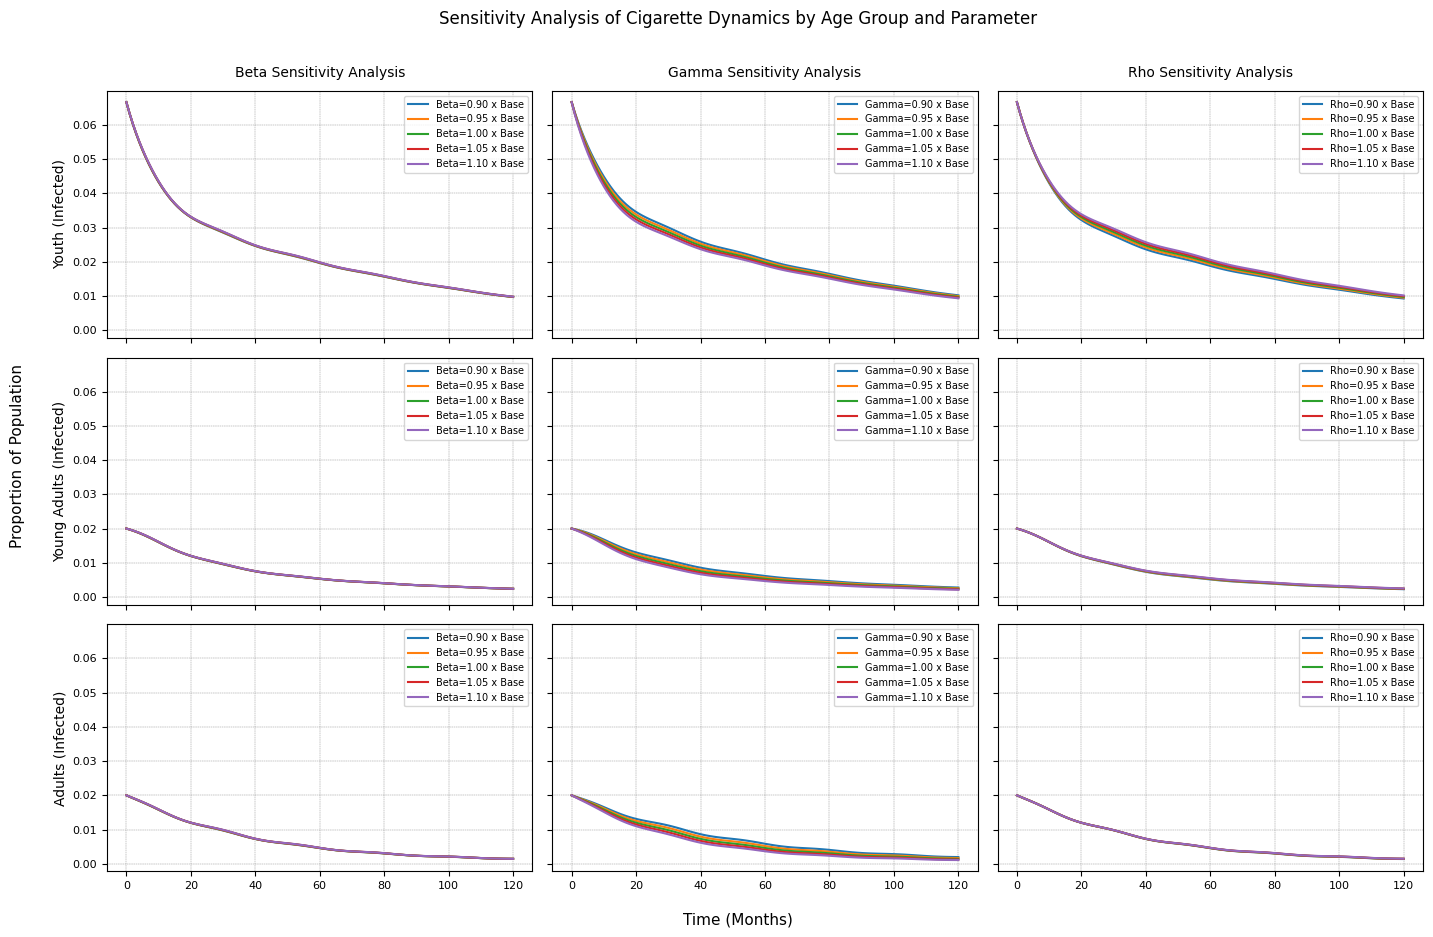

In [18]:
import matplotlib.pyplot as plt

# Plot results for all age groups
age_groups = ['Youth', 'Young Adults', 'Adults']
infected_indices = [1, 4, 7]  # Indices for infected states in each age group

# Initialize figure with a larger size
fig, axes = plt.subplots(3, len(results.keys()), figsize=(14, 9), sharex=True, sharey=True)

# Plotting sensitivity analysis for each parameter and age group
for col_idx, (key, sensitivity) in enumerate(results.items()):
    for row_idx, age_group in enumerate(age_groups):
        ax = axes[row_idx, col_idx]
        for factor, sol in sensitivity.items():
            ax.plot(t, sol[:, infected_indices[row_idx]], label=f'{key}={factor:.2f} x Base')
        # Set titles for the top row
        if row_idx == 0:
            ax.set_title(f'{key} Sensitivity Analysis', fontsize=10, pad=10)
        # Set Y-axis labels for the first column
        if col_idx == 0:
            ax.set_ylabel(f'{age_group} (Infected)', fontsize=10)
        # Add gridlines
        ax.grid(color='gray', linestyle='dashed', linewidth=0.3)
        ax.legend(fontsize=7)
        ax.tick_params(axis='both', labelsize=8)

# Add shared X and Y axis labels
if product_type == 'EC':    # E-Cigarettes
   stitle = 'Sensitivity Analysis of E-Cigarette Dynamics by Age Group and Parameter'
else:                       # Cigarettes
   stitle = 'Sensitivity Analysis of Cigarette Dynamics by Age Group and Parameter'
fig.text(0.5, 0.98, stitle, ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Proportion of Population', va='center', rotation='vertical', fontsize=11)
fig.text(0.5, -0.02, 'Time (Months)', ha='center', fontsize=11)

# Add a single legend outside the plot
handles, labels = ax.get_legend_handles_labels()
#fig.legend(handles, labels, loc='upper center', ncol=len(results.keys()), fontsize=10, frameon=False)
#fig.legend(handles)

# Adjust layout for better spacing
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the legend at the top

# Display the plot
plt.show()

# Sensitivity Analysis - E-Cigarette

In [19]:
product_type = 'EC'


import numpy as np
import matplotlib.pyplot as plt
from ddeint import ddeint
import pandas as pd

# Sensitivity ranges for beta, gamma, and rho (±10%)
beta_sensitivity_factors = np.linspace(0.9, 1.1, 5)  # 90% to 110% of base beta
gamma_sensitivity_factors = np.linspace(0.9, 1.1, 5)  # 90% to 110% of base gamma
rho_sensitivity_factors = np.linspace(0.9, 1.1, 5)  # 90% to 110% of base rho

# Base values for beta, gamma, and rho
if product_type == 'EC':    # E-Cigarettes
   beta_0 = 0.18  # Base infection coefficient for e-cigarettes
   gamma_0 = (1.333 ** (1 / 12) - 1)  # Base recovery coefficient for e-cigarettes
   rho_0 = (1.600 ** (1 / 12) - 1)  # Base relapse coefficient for e-cigarettes
else:                       # Cigarettes
   beta_0 = 0.003  # Base infection coefficient for e-cigarettes
   gamma_0 = (1.677 ** (1 / 12) - 1)  # Base recovery coefficient for e-cigarettes
   rho_0 = (1.912 ** (1 / 12) - 1)  # Base relapse coefficient for e-cigarettes

# Decay constants and seasonal variation
k_beta = 0.25  # Decay constant for beta
seasonal_amplitude = 0.005  # Seasonal variation for beta

# Functions to calculate parameters with sensitivity adjustment
def beta_values_sensitivity(t, factor=1.0):
    """Calculate beta values with sensitivity adjustment."""
    beta_base = beta_0 * np.exp(-k_beta * t / 12)  # Exponential decay
    beta_seasonal = seasonal_amplitude * np.cos(t / 12 * np.pi)  # Seasonal variation
    return factor * (beta_base + beta_seasonal)  # Adjust beta with sensitivity factor

def gamma_values_sensitivity(t, factor=1.0):
    """Calculate gamma values with sensitivity adjustment."""
    return factor * gamma_0

def rho_values_sensitivity(t, factor=1.0):
    """Calculate rho values with sensitivity adjustment."""
    return factor * rho_0

# Function to generate linearly spaced integers
def linspace_integers(start, stop, num):
    """Generate a linearly spaced array of integers."""
    step = (stop - start) // (num - 1)  # Calculate step using integer division
    return np.arange(start, stop + step, step, dtype=int)

# Generate time points
t_range = linspace_integers(0, 1019, 1020)

# Generate time points
t = np.linspace(0, 120, 120)  # Simulate for 10 years
t = t.astype('int32')

# Model definition
def model(Y, t, beta, gamma, rho):
    S_y, I_y, R_y, S_ya, I_ya, R_ya, S_a, I_a, R_a = Y(t)
    t_index = int(t)

    # Population dynamics for Youth
    dS_y_dt = B - beta[t_index] * S_y * I_y - mu * S_y - aging_rate_y_to_ya * S_y
    dI_y_dt = beta[t_index] * S_y * I_y - (mu + gamma[t_index]) * I_y + rho[t_index] * R_y - aging_rate_y_to_ya * I_y
    dR_y_dt = gamma[t_index] * I_y - (mu + rho[t_index]) * R_y - aging_rate_y_to_ya * R_y

    # Population dynamics for Young Adults
    dS_ya_dt = S_y * aging_rate_y_to_ya - beta[t_index] * S_ya * I_ya - mu * S_ya - aging_rate_ya_to_a * S_ya
    dI_ya_dt = I_y * aging_rate_y_to_ya + beta[t_index] * S_ya * I_ya - (mu + gamma[t_index]) * I_ya - aging_rate_ya_to_a * I_ya
    dR_ya_dt = R_y * aging_rate_y_to_ya + gamma[t_index] * I_ya - (mu + rho[t_index]) * R_ya - aging_rate_ya_to_a * R_ya

    # Population dynamics for Adults
    dS_a_dt = S_ya * aging_rate_ya_to_a - beta[t_index] * S_a * I_a - mu * S_a
    dI_a_dt = I_ya * aging_rate_ya_to_a + beta[t_index] * S_a * I_a - (mu + gamma[t_index]) * I_a
    dR_a_dt = R_ya * aging_rate_ya_to_a + gamma[t_index] * I_a - (mu + rho[t_index]) * R_a

    return [dS_y_dt, dI_y_dt, dR_y_dt, dS_ya_dt, dI_ya_dt, dR_ya_dt, dS_a_dt, dI_a_dt, dR_a_dt]

# Initial conditions
def history(t):
    return [0.8000, 0.2000, 0.0000, 0.9400, 0.0600, 0.0000, 0.9400, 0.0600, 0.0000]

# Sensitivity analysis for beta, gamma, and rho
results = {"Beta": {}, "Gamma": {}, "Rho": {}}

# Perform sensitivity analysis
for factor in beta_sensitivity_factors:
    beta = np.array([beta_values_sensitivity(t_i, factor) for t_i in t_range])
    gamma = np.array([gamma_values_sensitivity(t_i) for t_i in t_range])
    rho = np.array([rho_values_sensitivity(t_i) for t_i in t_range])
    sol = ddeint(model, history, t, fargs=(beta, gamma, rho))
    totals = sol.sum(axis=1)
    sol /= totals[:, None]
    results["Beta"][factor] = sol

for factor in gamma_sensitivity_factors:
    beta = np.array([beta_values_sensitivity(t_i) for t_i in t_range])
    gamma = np.array([gamma_values_sensitivity(t_i, factor) for t_i in t_range])
    rho = np.array([rho_values_sensitivity(t_i) for t_i in t_range])
    sol = ddeint(model, history, t, fargs=(beta, gamma, rho))
    totals = sol.sum(axis=1)
    sol /= totals[:, None]
    results["Gamma"][factor] = sol

for factor in rho_sensitivity_factors:
    beta = np.array([beta_values_sensitivity(t_i) for t_i in t_range])
    gamma = np.array([gamma_values_sensitivity(t_i) for t_i in t_range])
    rho = np.array([rho_values_sensitivity(t_i, factor) for t_i in t_range])
    sol = ddeint(model, history, t, fargs=(beta, gamma, rho))
    totals = sol.sum(axis=1)
    sol /= totals[:, None]
    results["Rho"][factor] = sol

# Plot results for Youth (example)
#plt.figure(figsize=(12, 8))
#for key, sensitivity in results.items():
#    plt.subplot(3, 1, list(results.keys()).index(key) + 1)
#    for factor, sol in sensitivity.items():
#        plt.plot(t, sol[:, 1], label=f'{key}={factor:.2f} x Base')  # Youth Infected
#    plt.title(f'Sensitivity Analysis of {key} for Youth (Infected)')
#    plt.xlabel('Time (Months)')
#    plt.ylabel('Proportion of Population')
#    plt.legend()
#    plt.grid()

#plt.tight_layout()
#plt.show()

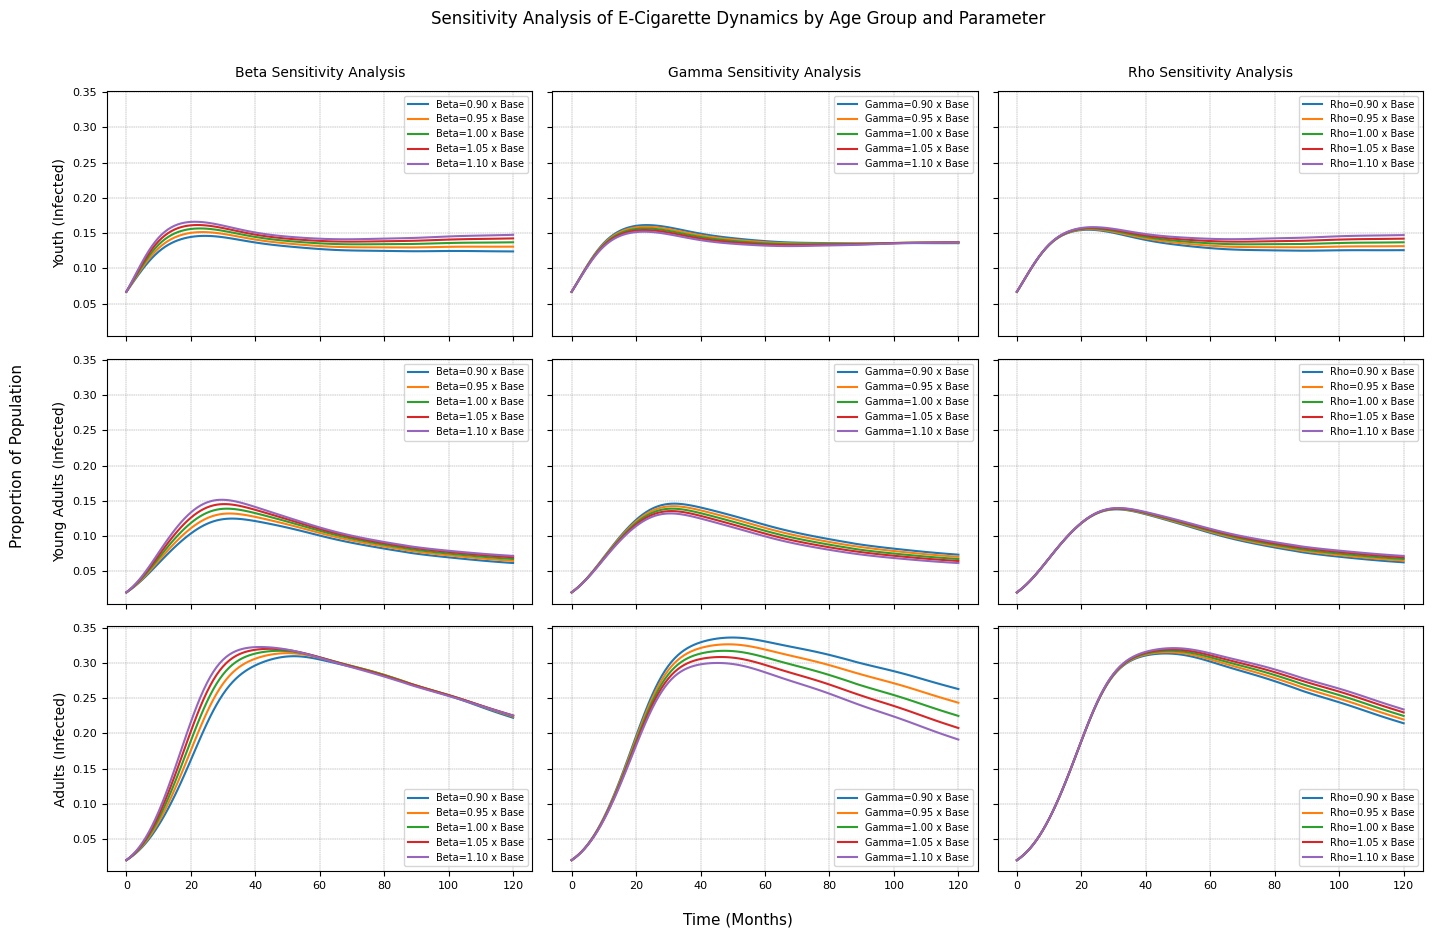

In [20]:
import matplotlib.pyplot as plt

# Plot results for all age groups
age_groups = ['Youth', 'Young Adults', 'Adults']
infected_indices = [1, 4, 7]  # Indices for infected states in each age group

# Initialize figure with a larger size
fig, axes = plt.subplots(3, len(results.keys()), figsize=(14, 9), sharex=True, sharey=True)

# Plotting sensitivity analysis for each parameter and age group
for col_idx, (key, sensitivity) in enumerate(results.items()):
    for row_idx, age_group in enumerate(age_groups):
        ax = axes[row_idx, col_idx]
        for factor, sol in sensitivity.items():
            ax.plot(t, sol[:, infected_indices[row_idx]], label=f'{key}={factor:.2f} x Base')
        # Set titles for the top row
        if row_idx == 0:
            ax.set_title(f'{key} Sensitivity Analysis', fontsize=10, pad=10)
        # Set Y-axis labels for the first column
        if col_idx == 0:
            ax.set_ylabel(f'{age_group} (Infected)', fontsize=10)
        # Add gridlines
        ax.grid(color='gray', linestyle='dashed', linewidth=0.3)
        ax.legend(fontsize=7)
        ax.tick_params(axis='both', labelsize=8)

# Add shared X and Y axis labels
if product_type == 'EC':    # E-Cigarettes
   stitle = 'Sensitivity Analysis of E-Cigarette Dynamics by Age Group and Parameter'
else:                       # Cigarettes
   stitle = 'Sensitivity Analysis of Cigarette Dynamics by Age Group and Parameter'
fig.text(0.5, 0.98, stitle, ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Proportion of Population', va='center', rotation='vertical', fontsize=11)
fig.text(0.5, -0.02, 'Time (Months)', ha='center', fontsize=11)

# Add a single legend outside the plot
handles, labels = ax.get_legend_handles_labels()
#fig.legend(handles, labels, loc='upper center', ncol=len(results.keys()), fontsize=10, frameon=False)
#fig.legend(handles)

# Adjust layout for better spacing
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the legend at the top

# Display the plot
plt.show()

# Map

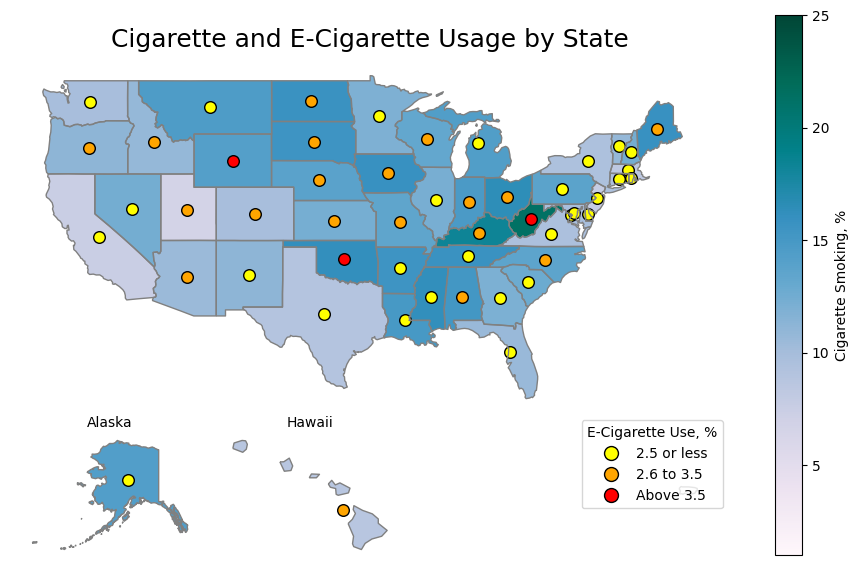

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from matplotlib.colors import ListedColormap
from shapely.geometry import Point

# Data
state_data = {
    "State": ["Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado", "Connecticut", "Delaware",
              "District of Columbia", "Florida", "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa",
              "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota",
              "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire", "New Jersey", "New Mexico",
              "New York", "North Carolina", "North Dakota", "Ohio", "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island",
              "South Carolina", "South Dakota", "Tennessee", "Texas", "Utah", "Vermont", "Virginia", "Washington", "West Virginia",
              "Wisconsin", "Wyoming"],
    "Cigarettes": [15.2, 14.3, 10.5, 15.5, 7.5, 9.9, 9.4, 10.7, 9.9, 10.6, 12, 8.7, 10.8, 12.2, 14.7, 15.9, 12.3, 18.3, 14.9, 15.9,
                    9.9, 8.4, 14.4, 11.9, 16.2, 13.5, 14.5, 13.8, 12.4, 12.4, 7.8, 11.2, 9.5, 13.6, 15.8, 16.4, 16.1, 11.2, 13.7, 8.4,
                    12.8, 15.5, 15.8, 9, 6.7, 10.8, 9.6, 9.9, 21.3, 13.2, 14.2],
    "E-cigarettes": [3.4, 2.2, 3.4, 2.5, 1.6, 3.2, 2, 1.4, 1.3, 1.7, 2.2, 2.7, 2.8, 2.3, 3, 3.1, 2.7, 3.5, 1.7, 3.3, 2.2, 1.8, 1.9,
                      1.5, 1.4, 2.7, 2.4, 3.2, 2, 2, 2.1, 2.5, 2.1, 2.7, 3.2, 2.8, 4.9, 3.2, 2.4, 0, 1.9, 3.5, 2, 2.3, 3, 1.9, 2.4,
                      2.3, 3.8, 2.6, 3.7]
}

# Create a DataFrame
data = pd.DataFrame(state_data)

# Load US States shape data
us_states = gpd.read_file("https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json")

# Standardize state names to uppercase for merging
data['State'] = data['State'].str.upper()
us_states['name'] = us_states['name'].str.upper()

# Merge the data with the map
us_map = us_states.merge(data, left_on='name', right_on='State', how='left')

# Separate Alaska and Hawaii for inset maps
continental_us = us_map[~us_map['name'].isin(['ALASKA', 'HAWAII'])]
alaska = us_map[us_map['name'] == 'ALASKA']
hawaii = us_map[us_map['name'] == 'HAWAII']

# Plotting
fig = plt.figure(figsize=(10, 6))
ax_main = plt.subplot(1, 1, 1)
ax_alaska = fig.add_axes([0.05, 0.05, 0.2, 0.2])  # Alaska inset
ax_hawaii = fig.add_axes([0.25, 0.05, 0.2, 0.2])  # Hawaii inset

# Define color map for cigarettes
#cmap = ListedColormap(['#c6dbef', '#6baed6', '#2171b5', '#08306b'])
#norm = plt.Normalize(vmin=8, vmax=20)  # Adjust based on the range of Cigarettes values

# Define color map for cigarettes with 8 orange ranges
#cmap = ListedColormap([
#    '#FFF7E6', '#FFE5CC', '#FFD2B3', '#FFBF99',
#    '#FFAB80', '#FF9966', '#FF804D', '#FF6633'
#])
cmap = 'PuBuGn'
norm = plt.Normalize(vmin=1, vmax=25)  # Adjust range for cigarettes

# Plot continental US
continental_us.boundary.plot(ax=ax_main, linewidth=1, color='gray')
continental_us.plot(column='Cigarettes', cmap=cmap, legend=True,
                    legend_kwds={'label': "Cigarette Smoking, %"}, norm=norm, ax=ax_main)

# Add e-cigarette usage circles to the main map
for idx, row in continental_us.iterrows():
    if not pd.isna(row['E-cigarettes']):
        color = 'yellow' if row['E-cigarettes'] <= 2.5 else \
                'orange' if row['E-cigarettes'] <= 3.5 else 'red'
        ax_main.scatter(row['geometry'].centroid.x, row['geometry'].centroid.y,
                        s=70, color=color, edgecolor='black', label="")

# Plot Alaska
alaska.boundary.plot(ax=ax_alaska, linewidth=1, color='gray')
alaska.plot(column='Cigarettes', cmap=cmap, legend=False, norm=norm, ax=ax_alaska)
for idx, row in alaska.iterrows():
    if not pd.isna(row['E-cigarettes']):
        color = 'yellow' if row['E-cigarettes'] <= 2.5 else \
                'orange' if row['E-cigarettes'] <= 3.5 else 'red'
        ax_alaska.scatter(row['geometry'].centroid.x, row['geometry'].centroid.y,
                          s=70, color=color, edgecolor='black')

# Plot Hawaii
hawaii.boundary.plot(ax=ax_hawaii, linewidth=1, color='gray')
hawaii.plot(column='Cigarettes', cmap=cmap, legend=False, norm=norm, ax=ax_hawaii)
for idx, row in hawaii.iterrows():
    if not pd.isna(row['E-cigarettes']):
        color = 'yellow' if row['E-cigarettes'] <= 2.5 else \
                'orange' if row['E-cigarettes'] <= 3.5 else 'red'
        ax_hawaii.scatter(row['geometry'].centroid.x, row['geometry'].centroid.y,
                          s=70, color=color, edgecolor='black')

# Style adjustments
ax_main.set_title("Cigarette and E-Cigarette Usage by State", fontsize=18)
ax_main.axis('off')
ax_alaska.set_title("Alaska", fontsize=10)
ax_alaska.axis('off')
ax_hawaii.set_title("Hawaii", fontsize=10)
ax_hawaii.axis('off')

# Custom legend for e-cigarette usage
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='2.5 or less', markerfacecolor='yellow', markersize=10, markeredgecolor='black'),
    Line2D([0], [0], marker='o', color='w', label='2.6 to 3.5', markerfacecolor='orange', markersize=10, markeredgecolor='black'),
    Line2D([0], [0], marker='o', color='w', label='Above 3.5', markerfacecolor='red', markersize=10, markeredgecolor='black'),
]
ax_main.legend(handles=legend_elements, title="E-Cigarette Use, %", loc='lower right')

#plt.tight_layout()
# Adjust spacing instead of using plt.tight_layout()
plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05, wspace=0.2, hspace=0.2)

# Show the plot
plt.show()